# **This is a notebook to create a unified json file for East Africa countries from GADM json single country files**

In [4]:
import geopandas as gpd
import pandas as pd 
import os
import geopandas as gpd
from shapely.geometry import Point

✅ Loaded: bdi_gdf
✅ Loaded: cod_gdf
✅ Loaded: dji_gdf
✅ Loaded: eri_gdf
✅ Loaded: eth_gdf
✅ Loaded: ken_gdf
✅ Loaded: rwa_gdf
✅ Loaded: sdn_gdf
✅ Loaded: som_gdf
✅ Loaded: ssd_gdf
✅ Loaded: tza_gdf
✅ Loaded: uga_gdf

💾 Merged GeoJSON saved as: east_africa_level1_merged.geojson


<Axes: >

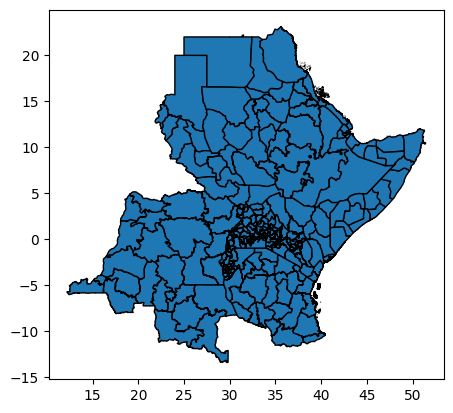

In [13]:
import geopandas as gpd
import pandas as pd
import os

# List of East African country ISO codes (GADM format)
countries = ["BDI", 'COD', 'DJI', 'ERI', 'ETH', 'KEN', 'RWA', 'SDN', 'SOM', 'SSD', 'TZA', 'UGA']

# File naming pattern
prefix = 'gadm41_'
suffix = '_1.json'
geojson_dir = '../data/'  # your directory path

# Dictionary to store individual GeoDataFrames
gdfs = {}

# Load each country's GeoJSON file into its own GeoDataFrame
for iso in countries:
    file_path = os.path.join(geojson_dir, f"{prefix}{iso}{suffix}")
    
    if os.path.exists(file_path):
        gdf = gpd.read_file(file_path)
        var_name = iso.lower() + "_gdf"  # e.g., uga_gdf
        gdfs[var_name] = gdf
        print(f"✅ Loaded: {var_name}")
    else:
        print(f"⚠️ File not found: {file_path}")

# Merge all GeoDataFrames into one
merged_gdf = pd.concat(gdfs.values(), ignore_index=True)
merged_gdf = gpd.GeoDataFrame(merged_gdf, crs=merged_gdf.crs)

# Save merged file (optional)
merged_gdf.to_file("east_africa_level1_merged.geojson", driver="GeoJSON")
print("\n💾 Merged GeoJSON saved as: east_africa_level1_merged.geojson")

# Optional: Plot merged result
merged_gdf.plot(edgecolor='black')

In [19]:
merged_gdf["COUNTRY"].unique()

array(['Burundi', 'DemocraticRepublicoftheCongo', 'Djibouti', 'Eritrea',
       'Ethiopia', 'Kenya', 'Rwanda', 'Sudan', 'Somalia', 'SouthSudan',
       'Tanzania', 'Uganda'], dtype=object)

In [20]:
merged_gdf[merged_gdf["COUNTRY"]=="DemocraticRepublicoftheCongo"]

,GID_1,GID_0,COUNTRY,NAME_1,VARNAME_1,NL_NAME_1,TYPE_1,ENGTYPE_1,CC_1,HASC_1,ISO_1,geometry
17,COD.1_1,COD,DemocraticRepublicoftheCongo,Bas-Uele,NA,NA,Province,Province,NA,CD.BU,NA,"MULTIPOLYGON (((23.5429 2.4456, 23.5364 2.4513..."
18,COD.2_1,COD,DemocraticRepublicoftheCongo,Équateur,NA,NA,Province,Province,NA,CD.ET,NA,"MULTIPOLYGON (((17.1136 -1.7864, 17.1076 -1.78..."
19,COD.3_1,COD,DemocraticRepublicoftheCongo,Haut-Katanga,NA,NA,Province,Province,NA,CD.HK,CD-HK,"MULTIPOLYGON (((28.5232 -11.882, 28.5486 -11.8..."
20,COD.4_1,COD,DemocraticRepublicoftheCongo,Haut-Lomami,NA,NA,Province,Province,NA,CD.HL,NA,"MULTIPOLYGON (((25.498 -9.4957, 25.5025 -9.503..."
21,COD.5_1,COD,DemocraticRepublicoftheCongo,Haut-Uele,NA,NA,Province,Province,NA,CD.HU,NA,"MULTIPOLYGON (((28.3139 2.3361, 28.3168 2.3144..."
22,COD.6_1,COD,DemocraticRepublicoftheCongo,Ituri,NA,NA,Province,Province,NA,CD.IT,CD-IT,"MULTIPOLYGON (((30.5787 1.3101, 30.562 1.2822,..."
23,COD.9_1,COD,DemocraticRepublicoftheCongo,Kasaï,NA,NA,Province,Province,NA,CD.KS,NA,"MULTIPOLYGON (((21.2038 -7.2788, 21.2052 -7.28..."
24,COD.7_1,COD,DemocraticRepublicoftheCongo,Kasaï-Central,NA,NA,Province,Province,NA,CD.LL,NA,"MULTIPOLYGON (((21.8445 -7.6087, 21.8477 -7.60..."
25,COD.8_1,COD,DemocraticRepublicoftheCongo,Kasaï-Oriental,NA,NA,Province,Province,NA,CD.KO,NA,"MULTIPOLYGON (((23.8082 -6.3904, 23.8087 -6.39..."
26,COD.10_1,COD,DemocraticRepublicoftheCongo,Kinshasa,NA,NA,Province,Province,NA,CD.KN,CD-KN,"MULTIPOLYGON (((16.2571 -4.97, 16.1525 -4.9678..."


In [21]:
import geopandas as gpd
import os
import glob
import pandas as pd

shp_folder = "/home/kimani/Documents/EA_SHAPE_FILES/admin_zero"
shp_files = glob.glob(os.path.join(shp_folder, "*_0.shp"))

print(f"Found {len(shp_files)} Level 0 shapefiles")

gdf_list = []

for shp in shp_files:
    gdf = gpd.read_file(shp)
    gdf_list.append(gdf)
    print(f"Loaded {os.path.basename(shp)}")

all_gdf = gpd.GeoDataFrame(pd.concat(gdf_list, ignore_index=True), crs=gdf_list[0].crs)

# Merge by country name to keep separate countries
merged_gdf = all_gdf.dissolve(by='GID_0')

output_path = "/home/kimani/Documents/EA_SHAPE_FILES/east_africa_level0_merged.shp"
merged_gdf.to_file(output_path)

print(f"\n✅ Merged shapefile saved to: {output_path}")

Found 12 Level 0 shapefiles
Loaded gadm41_TZA_0.shp
Loaded gadm41_RWA_0.shp
Loaded gadm41_KEN_0.shp
Loaded gadm41_UGA_0.shp
Loaded gadm41_SDN_0.shp
Loaded gadm41_COD_0.shp
Loaded gadm41_DJI_0.shp
Loaded gadm41_BDI_0.shp
Loaded gadm41_ERI_0.shp
Loaded gadm41_ETH_0.shp
Loaded gadm41_SSD_0.shp
Loaded gadm41_SOM_0.shp

✅ Merged shapefile saved to: /home/kimani/Documents/EA_SHAPE_FILES/east_africa_level0_merged.shp


In [24]:
all_gdf.columns

Index(['GID_0', 'COUNTRY', 'geometry'], dtype='object')